# Exploración de datos — UCI Adult (Census Income)

**Antonio Díaz** · TC5061 MLOps · Tecnológico de Monterrey

Este notebook se conserva **únicamente para la exploración y el diagnóstico de calidad de los datos** (Pasos 1 a 3). El preprocesamiento, el entrenamiento, la evaluación y el registro en MLflow viven en `train.py`, que replica exactamente las decisiones de limpieza documentadas aquí.

**Problema:** clasificación binaria. Predecir si el ingreso anual supera los 50 000 USD (`>50K`) a partir de 14 variables del censo de EE. UU. de 1994.

**Fuente:** Becker, B. & Kohavi, R. (1996). *Adult*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/2/adult

In [1]:
import warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 20)

## Paso 1. Carga y descripción del dataset

El archivo `adult.data` no trae encabezado; los nombres de columna se toman de `adult.names`. Los valores faltantes vienen codificados como `?` y los textos traen un espacio inicial.

In [2]:
COLUMNAS = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
            "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
            "hours_per_week", "native_country", "income"]

df = pd.read_csv("../data/adult.data", header=None, names=COLUMNAS, skipinitialspace=True)
print(f"Registros: {df.shape[0]:,}   Variables: {df.shape[1]}")
df.head()

Registros: 32,561   Variables: 15


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


### Significado de las variables

Numéricas:

- `age`: edad en años.
- `fnlwgt`: peso muestral del censo (cuántas personas representa el registro).
- `education_num`: nivel educativo codificado del 1 al 16.
- `capital_gain` y `capital_loss`: ganancias y pérdidas de capital en el año, en USD.
- `hours_per_week`: horas trabajadas por semana.

Categóricas:

- `workclass`: tipo de empleador (privado, gobierno, autoempleo, etc.).
- `education`: máximo nivel educativo alcanzado, en texto.
- `marital_status`: estado civil.
- `occupation`: ocupación.
- `relationship`: rol en el hogar (esposo/a, hijo/a, no familiar, etc.).
- `race` y `sex`: grupo racial y sexo.
- `native_country`: país de origen.

Objetivo:

- `income`: `<=50K` o `>50K`.

En total hay 6 variables numéricas, 8 categóricas y la variable objetivo. `education` y `education_num` codifican la misma información; `fnlwgt` es un peso de muestreo, no una característica de la persona.

## Paso 2. Análisis exploratorio (EDA)

### 2.1 Estadísticas descriptivas

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0


In [5]:
df.describe(include="object").T

,count,unique,top,freq
workclass,32561,9,Private,22696
education,32561,16,HS-grad,10501
marital_status,32561,7,Married-civ-spouse,14976
occupation,32561,15,Prof-specialty,4140
relationship,32561,6,Husband,13193
race,32561,5,White,27816
sex,32561,2,Male,21790
native_country,32561,42,United-States,29170
income,32561,2,<=50K,24720


Observaciones iniciales: `capital_gain` y `capital_loss` tienen mediana 0 y valores máximos muy alejados (99 999 y 4 356), es decir, están concentradas en cero con una cola larga. `hours_per_week` va de 1 a 99 con mediana 40. `native_country` está dominada por Estados Unidos (29 170 de 32 561 registros). Varias categóricas muestran `?` como una de sus categorías: son faltantes codificados.

### 2.2 Variable objetivo

        registros  porcentaje
income                       
<=50K       24720        75.9
>50K         7841        24.1


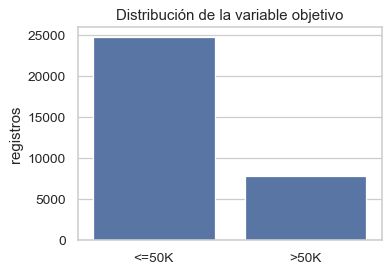

In [6]:
conteo = df["income"].value_counts()
prop = df["income"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"registros": conteo, "porcentaje": prop}))

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.countplot(data=df, x="income", ax=ax)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel(""); ax.set_ylabel("registros")
plt.tight_layout(); plt.show()

El dataset está **desbalanceado**: aproximadamente 76 % de los registros son `<=50K` y 24 % `>50K`. Esto implica que un clasificador trivial que siempre prediga `<=50K` alcanzaría ~76 % de exactitud, por lo que la *accuracy* sola no es suficiente para evaluar el modelo; se complementará con precisión, recall, F1 y ROC-AUC.

### 2.3 Distribución de las variables numéricas

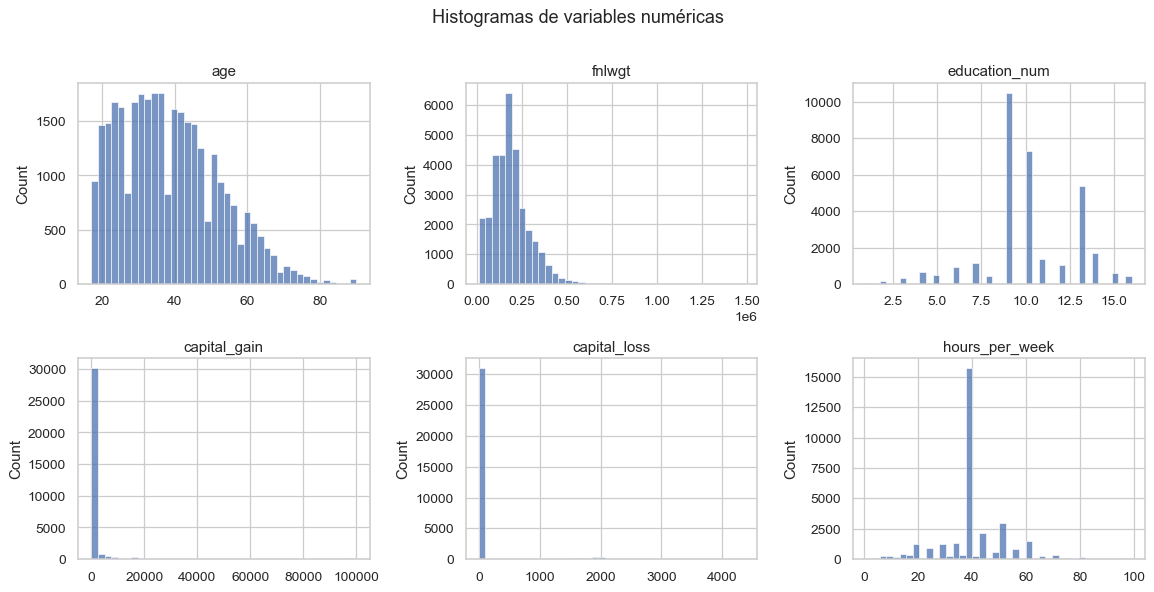

In [7]:
numericas = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), numericas):
    sns.histplot(df[col], bins=40, ax=ax, kde=False)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Histogramas de variables numéricas", y=1.01)
plt.tight_layout(); plt.show()

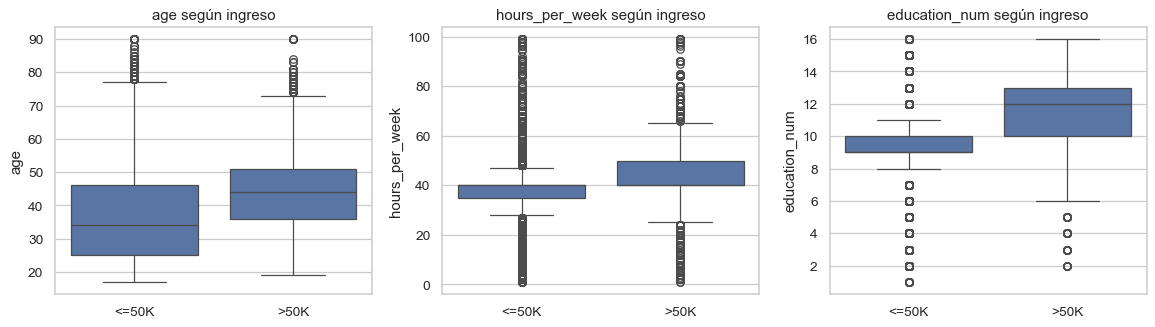

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["age", "hours_per_week", "education_num"]):
    sns.boxplot(data=df, x="income", y=col, ax=ax)
    ax.set_title(f"{col} según ingreso"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Las personas con ingreso `>50K` tienden a ser mayores (mediana 44 vs 34 años), con más años de educación (mediana 12 vs 9) y jornadas más largas en el cuartil superior, aunque la mediana de horas es 40 en ambos grupos. `capital_gain` y `capital_loss` son fuertemente asimétricas: la gran mayoría vale cero. `fnlwgt` no muestra relación con el ingreso, lo que refuerza que es un peso muestral y no una característica predictiva.

### 2.4 Variables categóricas frente al objetivo

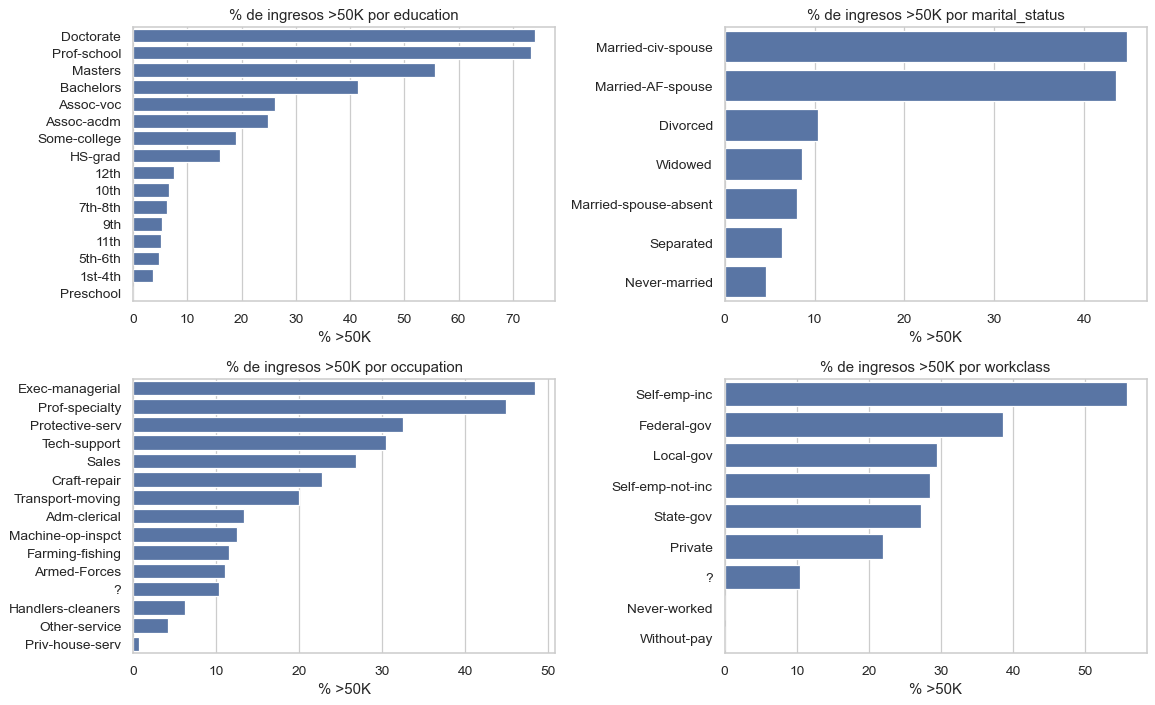

In [9]:
def tasa_por_categoria(col, top=None):
    t = df.groupby(col)["income"].apply(lambda s: (s == ">50K").mean() * 100)
    n = df[col].value_counts()
    out = pd.DataFrame({"registros": n, "% >50K": t.round(1)}).sort_values("% >50K", ascending=False)
    return out.head(top) if top else out

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ["education", "marital_status", "occupation", "workclass"]):
    t = tasa_por_categoria(col)
    sns.barplot(x=t["% >50K"], y=t.index, ax=ax, orient="h")
    ax.set_title(f"% de ingresos >50K por {col}"); ax.set_ylabel(""); ax.set_xlabel("% >50K")
plt.tight_layout(); plt.show()

In [10]:
tasa_por_categoria("sex"), tasa_por_categoria("relationship")

(        registros  % >50K
 sex                      
 Male        21790    30.6
 Female      10771    10.9,
                 registros  % >50K
 relationship                     
 Wife                 1568    47.5
 Husband             13193    44.9
 Not-in-family        8305    10.3
 Unmarried            3446     6.3
 Other-relative        981     3.8
 Own-child            5068     1.3)

La tasa de ingresos altos crece de forma casi monótona con el nivel educativo (de 0 % en preescolar a 74 % en doctorado). El estado civil y la relación en el hogar separan fuertemente las clases: las personas casadas (`Married-civ-spouse`, `Husband`, `Wife`) tienen tasas de 44–48 %, frente a 10 % o menos en el resto. Las ocupaciones ejecutivas (48 %) y profesionales (45 %) son las de mayor tasa. La brecha por sexo es grande: 30.6 % de los hombres frente a 10.9 % de las mujeres. Estas variables son candidatas claras a ser informativas para el modelo.

### 2.5 Correlaciones entre variables numéricas

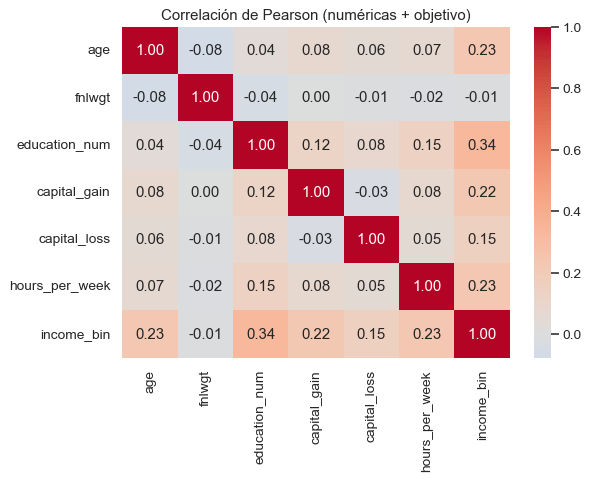

In [11]:
df_corr = df[numericas].copy()
df_corr["income_bin"] = (df["income"] == ">50K").astype(int)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación de Pearson (numéricas + objetivo)")
plt.tight_layout(); plt.show()

Ninguna variable numérica tiene una correlación fuerte con el objetivo; las mayores son `education_num` (0.34), `age` (0.23), `hours_per_week` (0.23) y `capital_gain` (0.22). No hay colinealidad problemática entre las numéricas. `fnlwgt` tiene correlación prácticamente nula con todo (−0.01 con el objetivo), lo que confirma la decisión de descartarla.

## Paso 3. Limpieza de datos

### 3.1 Valores faltantes

In [12]:
df_clean = df.replace("?", np.nan)

faltantes = df_clean.isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("faltantes")
faltantes["%"] = (faltantes["faltantes"] / len(df_clean) * 100).round(2)
print(faltantes)

filas_con_nan = df_clean.isna().any(axis=1).sum()
print(f"\nFilas con al menos un faltante: {filas_con_nan:,} ({filas_con_nan/len(df_clean)*100:.2f} %)")

                faltantes     %
workclass            1836  5.64
occupation           1843  5.66
native_country        583  1.79

Filas con al menos un faltante: 2,399 (7.37 %)


In [13]:
# Los faltantes de workclass y occupation ocurren casi siempre en las mismas filas
pd.crosstab(df_clean["workclass"].isna(), df_clean["occupation"].isna(),
            rownames=["workclass NaN"], colnames=["occupation NaN"])

occupation NaN,False,True
workclass NaN,,
False,30718,7
True,0,1836


**Decisión:** eliminar las 2 399 filas con faltantes (7.4 % del dataset).

Justificación: (1) los faltantes se concentran en tres variables categóricas y casi siempre coinciden en la misma fila (`workclass` y `occupation`), lo que sugiere personas sin empleo registrado, no errores de captura dispersos; (2) imputar la moda (`Private`, `Prof-specialty`) inventaría una ocupación para quien no la tiene y sesgaría esas categorías; (3) el volumen perdido es pequeño y quedan más de 30 000 registros, suficientes para un baseline. La alternativa de crear una categoría explícita `Unknown` queda documentada como mejora futura.

### 3.2 Duplicados

In [14]:
antes = len(df_clean)
df_clean = df_clean.dropna()
print(f"Tras eliminar faltantes: {len(df_clean):,} filas ({antes - len(df_clean):,} eliminadas)")

dup = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f"Duplicados exactos eliminados: {dup}   ->  {len(df_clean):,} filas")

Tras eliminar faltantes: 30,162 filas (2,399 eliminadas)
Duplicados exactos eliminados: 23   ->  30,139 filas


**Decisión:** eliminar los duplicados exactos. Son filas idénticas en las 15 columnas; mantenerlas daría doble peso a esas observaciones y podría filtrar la misma fila a entrenamiento y prueba, inflando la métrica.

### 3.3 Outliers

In [15]:
def resumen_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    return pd.Series({"min": s.min(), "p99": s.quantile(0.99), "max": s.max(),
                      "outliers_IQR": n_out, "% outliers": round(n_out / len(s) * 100, 1)})

pd.DataFrame({c: resumen_outliers(df_clean[c]) for c in numericas}).T

,min,p99,max,outliers_IQR,% outliers
age,17.0,72.00,90.0,168.0,0.6
fnlwgt,13769.0,511205.02,1484705.0,904.0,3.0
education_num,1.0,16.00,16.0,193.0,0.6
capital_gain,0.0,15024.00,99999.0,2538.0,8.4
capital_loss,0.0,1980.00,4356.0,1427.0,4.7
hours_per_week,1.0,80.00,99.0,7947.0,26.4


In [16]:
print("Registros con capital_gain = 99999:", (df_clean["capital_gain"] == 99999).sum())
print("Registros con hours_per_week = 99 :", (df_clean["hours_per_week"] == 99).sum())
print("Registros con age >= 90          :", (df_clean["age"] >= 90).sum())
print("\nIngreso de quienes tienen capital_gain = 99999:")
print(df_clean.loc[df_clean["capital_gain"] == 99999, "income"].value_counts())

Registros con capital_gain = 99999: 148
Registros con hours_per_week = 99 : 78
Registros con age >= 90          : 34

Ingreso de quienes tienen capital_gain = 99999:
income
>50K    148
Name: count, dtype: int64


**Decisión:** conservar los outliers, con dos matices.

- `capital_gain` y `capital_loss`: el criterio IQR marca como outlier a todo valor distinto de cero porque la mediana es 0; no son errores sino la naturaleza de la variable. El valor 99 999 (148 registros tras la limpieza, todos `>50K`) es un tope de codificación del censo, pero es informativo para el problema, así que se mantiene. Para reducir el efecto de la asimetría en el modelo lineal se aplica `log1p` a ambas variables.
- `age` (máx. 90) y `hours_per_week` (máx. 99): son valores plausibles y poco frecuentes; el escalado estándar los acota lo suficiente para una regresión logística.

Eliminar estas filas descartaría casos reales de la clase minoritaria, justo la que más interesa predecir.

### 3.4 Tipos y variables redundantes

In [17]:
# Objetivo a binario, log1p en ganancias/pérdidas, descarte de redundantes
df_clean["income_bin"] = (df_clean["income"] == ">50K").astype(int)
df_clean["capital_gain_log"] = np.log1p(df_clean["capital_gain"])
df_clean["capital_loss_log"] = np.log1p(df_clean["capital_loss"])
df_clean = df_clean.drop(columns=["fnlwgt", "education", "income", "capital_gain", "capital_loss"])

for c in df_clean.select_dtypes("object").columns:
    df_clean[c] = df_clean[c].astype("category")

print(f"Dataset limpio: {df_clean.shape[0]:,} filas x {df_clean.shape[1]} columnas")
df_clean.dtypes

Dataset limpio: 30,139 filas x 13 columnas


age                    int64
workclass           category
education_num          int64
marital_status      category
occupation          category
relationship        category
race                category
sex                 category
hours_per_week         int64
native_country      category
income_bin             int64
capital_gain_log     float64
capital_loss_log     float64
dtype: object

**Decisiones sobre tipos y columnas:**

- `income` → `income_bin` (0 = `<=50K`, 1 = `>50K`), formato que esperan las métricas de scikit-learn.
- Se elimina `fnlwgt`: es un peso de muestreo del censo, no una característica de la persona, y no correlaciona con el objetivo.
- Se elimina `education`: es la versión textual de `education_num`; conservar ambas duplicaría la información.
- Las categóricas se convierten al tipo `category` para dejar explícito su rol; el *one-hot encoding* se hace dentro del pipeline para evitar fuga de información entre entrenamiento y prueba.

### 3.5 Resumen de la limpieza

- Se eliminaron las 2 399 filas (7.4 %) con valores faltantes en `workclass`, `occupation` o `native_country`.
- Se eliminaron 23 filas duplicadas.
- Los outliers se conservaron; a `capital_gain` y `capital_loss` se les aplicó `log1p` para suavizar la cola larga.
- La variable objetivo pasó de texto a 0/1 y las categóricas al tipo `category`.
- Se descartaron `education` (duplica a `education_num`) y `fnlwgt` (sin valor predictivo).

El dataset limpio queda con 30 139 filas y 13 columnas.